In [55]:
from typing import Callable

import duckdb
import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import ArrayLike
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator
from sklearn.compose import ColumnTransformer
from sklearn.metrics import root_mean_squared_error, mean_squared_error
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils import check_X_y, check_array
from scipy.sparse import csr_array, issparse, hstack

# from recommender import recommender_scorer

In [3]:
def _predict_y_fm(X, intercept, weights, factors):
    X_dot_factors = X @ factors
    X_dot_factors_squares = X ** 2 @ (factors ** 2)
    interactions = np.sum(X_dot_factors ** 2 - X_dot_factors_squares, axis=1) / 2
    linear_part = X @ weights
    return intercept + linear_part + interactions, X_dot_factors


def _process_X_y(X, y):
    X, y = check_X_y(X, y, accept_sparse=["csr"])
    if issparse(X):
        X = csr_array(X)
    return X, y


class FactorizationMachine(BaseEstimator):
    def __init__(
            self, 
            factors_num: int = 1, 
            max_iter=1000,
            tol=1e-3,
            learn_rate=0.01,
            loss: str | Callable[[ArrayLike, ArrayLike], float] = "mse",
            dloss_dpred: Callable[[ArrayLike, ArrayLike], ArrayLike] | None = None,
            weights_penalty=0.00001,
            factors_penalty=0,
            batch_size=1000,
            patience=3,
            random_state=None,
            verbose=False,
    ):
        self.factors_num = factors_num
        self.max_iter = max_iter
        self.tol = tol
        self.learn_rate = learn_rate
        if loss == "mse":
            self.loss = lambda y, y_pred: np.mean((y - y_pred) ** 2)
            self.dloss_dpred = lambda y, y_pred: 2 * (y_pred - y) / y.shape[0]
        else:
            self.loss = loss
            self.dloss_dpred = dloss_dpred

        self.patience = patience
        self.batch_size = batch_size
        self.random_state = random_state
        self.weights_penalty = weights_penalty
        self.factors_penalty = factors_penalty
        self.verbose = verbose

    def fit(
            self,
            X: ArrayLike,
            y: ArrayLike,
            eval_set: tuple[ArrayLike, ArrayLike] | None = None,
    ):
        X, y = _process_X_y(X, y)
        if eval_set is not None:
            X_val, y_val = _process_X_y(eval_set[0], eval_set[1])
        n_samples, dim = X.shape
        rng = np.random.default_rng(seed=self.random_state)
        self._intercept = np.mean(y)
        self._weights = np.zeros(shape=(dim,), dtype=float)
        self._factors = rng.normal(scale=0.1, size=(dim, self.factors_num))
        no_improvement_count = 0
        best_val_score = -np.inf

        for iter in range(self.max_iter):
            permutation = rng.permutation(n_samples)

            for i in range(0, n_samples, self.batch_size):
                batch_indices = permutation[i : i + self.batch_size]
                X_batch = X[batch_indices]
                y_batch = y[batch_indices]
                y_pred_batch, X_dot_factors = self._predict(X_batch)

                dloss_dpred = self.dloss_dpred(y_batch, y_pred_batch)
                self._intercept -= self.learn_rate * np.sum(dloss_dpred)

                weights_grad = X_batch.T @ dloss_dpred \
                            + 2 * self.weights_penalty * self._weights
                self._weights -= self.learn_rate * weights_grad

                factor_coef_0 = X_batch.T @ (dloss_dpred[:, np.newaxis] * X_dot_factors)
                factor_coef_1 = -(X_batch.T ** 2) @ dloss_dpred
                factors_grad = factor_coef_0 \
                                + factor_coef_1[:, np.newaxis] * self._factors \
                                + 2 * self.factors_penalty * self._factors
                
                factors_change = 10 * self.learn_rate * factors_grad
                factors_change_norm = np.linalg.norm(factors_change)
                max_change_norm = 0.05
                if factors_change_norm > max_change_norm:
                    factors_change = factors_change * (max_change_norm  / factors_change_norm)
                self._factors -= factors_change
            y_pred = self._predict(X)[0]
            curr_loss = self.loss(y_pred, y)

            if eval_set is None:
                if  iter > 0 and abs(curr_loss - prev_loss) < self.tol:
                    no_improvement_count += 1
                else:
                    no_improvement_count = 0
                prev_loss = curr_loss

            else:
                val_score = self.score(X_val, y_val)
                if val_score > best_val_score + self.tol:
                    best_val_score = val_score
                    no_improvement_count = 0
                else:
                    no_improvement_count += 1

            if no_improvement_count >= self.patience:
                self.fitted_ = True
                self.n_iter = iter
                return self


            if self.verbose == True and iter % 10 == 0:
                print(
                    f"Iteration {iter}, factors num {self.factors_num}, \n"
                    f"factors abs mean: {np.mean(np.abs(self._factors))}, \n"
                    f"weights abs mean: {np.mean(np.abs(self._weights))}, \n"
                    f"intercept {self._intercept}, validation rmse {val_score}"
                )


        self.n_iter = self.max_iter
        self.fitted_ = True
        return self

    def _predict(self, X):
        return _predict_y_fm(X, self._intercept, self._weights, self._factors)

    def predict(self, X):
        X = check_array(X, accept_sparse=["csr"])
        if issparse(X):
            X = csr_array(X)
        return self._predict(X)[0]

    def score(self, X, y):
        y_pred = self.predict(X)
        return -root_mean_squared_error(y, y_pred)



In [4]:
rng = np.random.default_rng()
toy_shape = (1000, 10)
factors_num = 4
X = rng.normal(size=toy_shape)

intercept = -100
weights = np.ones(shape=(X.shape[1],))
factors = rng.normal(size=(X.shape[1], factors_num))

y = _predict_y_fm(X, intercept, weights, factors)[0]
y += rng.normal(scale=abs(y.mean()) * 0.05)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, train_size=0.5)

fm = GridSearchCV(
    estimator=FactorizationMachine(max_iter=10000, random_state=42, batch_size=300),
    param_grid={
        "factors_num": [1, 3, 4, 5, 10],
    }
)

fm.fit(X_train, y_train, eval_set=(X_val, y_val))

,estimator,Factorization...ndom_state=42)
,param_grid,"{'factors_num': [1, 3, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,factors_num,5


In [6]:
fm.best_estimator_.n_iter

102

In [7]:
fm.best_params_

{'factors_num': 5}

In [8]:
fm.score(X_test, y_test)

-0.24530503580972862

Text(0, 0.5, 'FM prediction')

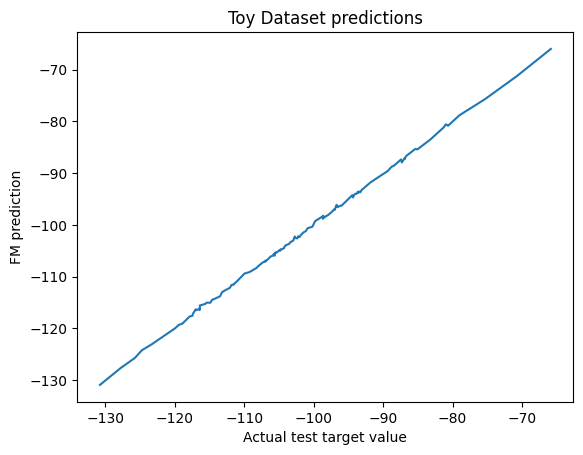

In [9]:
y_pred = fm.predict(X_test)

sns.lineplot(x=y_test, y=y_pred)
plt.title("Toy Dataset predictions")
plt.xlabel("Actual test target value")
plt.ylabel("FM prediction")


## Movies dataset

MovieLens100k and MovieLens1M can't be used together -- users' ids don't match.

In [10]:
with duckdb.connect("/home/maria-khanina/mkgit/movies_project/data/database.duckdb", read_only=True) as db_conn:
    ratings_df = db_conn.execute("""
        SELECT *
        FROM ratings INNER JOIN movies USING (movie_id)
    """).df()


In [11]:
ratings_df.head()

,user_id,movie_id,rating,timestamp,title,genres
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama
1,1,661,3,978302109,James and the Giant Peach (1996),Animation|Children's|Musical
2,1,914,3,978301968,My Fair Lady (1964),Musical|Romance
3,1,3408,4,978300275,Erin Brockovich (2000),Drama
4,1,2355,5,978824291,"Bug's Life, A (1998)",Animation|Children's|Comedy


In [12]:
ratings_df.shape

(1000209, 6)

In [13]:
ratings_df.isna().sum()

user_id      0
movie_id     0
rating       0
timestamp    0
title        0
genres       0
dtype: int64

In [14]:
ratings_df["rating"].value_counts().sort_index()

rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64

In [15]:
X = ratings_df[["user_id", "movie_id"]]
y = ratings_df["rating"]

In [52]:
groupby_user = ratings_df.groupby("user_id")
time_range = groupby_user["timestamp"].max() - groupby_user["timestamp"].min()
days_range = time_range / (60 * 60 * 24)

In [53]:
days_range.min(), days_range.median(), days_range.max()

(np.float64(0.0012268518518518518),
 np.float64(0.04708912037037037),
 np.float64(1032.9605555555556))

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.01,
    random_state=42,
)

In [17]:
X_val, X_test, y_val, y_test = train_test_split(
    X_test, y_test,
    test_size=0.5,
    random_state=42,
)

### Average train rating as prediction

In [18]:
df_train = pd.concat((X_train, y_train), axis="columns")
avg_total = df_train["rating"].mean()
avg_train_ratings = df_train.groupby("movie_id", as_index=False)["rating"].mean()
avg_train_ratings.columns = ["movie_id", "avg_movie_rating"]
df_train = pd.merge(left=df_train, right=avg_train_ratings, on="movie_id")

In [19]:
df_val = pd.merge(left=X_val, right=avg_train_ratings, on="movie_id", how="left")
df_val["avg_movie_rating"] = df_val["avg_movie_rating"].fillna(avg_total)

In [20]:
root_mean_squared_error(y_val, df_val["avg_movie_rating"])

0.9694711350390633

### Factorization Machine with only encoded user_id and movie_id as features

In [21]:
all_users = np.sort(X_train["user_id"].unique())
all_movies = np.sort(X_train["movie_id"].unique())

In [ ]:
base_fm = Pipeline(
    steps=[
        ("encode", OneHotEncoder(
            categories=[all_users, all_movies],
            handle_unknown="ignore",
        )),
        ("predict", FactorizationMachine(
            factors_num=20,
            weights_penalty=0,
            factors_penalty=0,
            batch_size=1000,
            verbose=True,
        ))
    ]
)

In [23]:
base_search = GridSearchCV(
    estimator=base_fm,
    param_grid={
        "predict__factors_num": [10, 20, 30],
    },
    verbose=100,
    cv=5,
)

In [24]:
X_val_preprocessed = base_fm[:-1].fit(X_train).transform(X_val)

In [ ]:
base_search.fit(X_train, y_train, predict__eval_set=(X_val_preprocessed, y_val))

In [ ]:
y_pred = base_search.predict(X_val)

In [ ]:
y_pred = np.clip(y_pred, 1, 5)
root_mean_squared_error(y_val, y_pred)

0.9545918472310234

In [ ]:
base_search.best_params_

{'predict__factors_num': 10}

### Factorization Machine with movies genres added as features

### Factorization Machine with user's preferences added to features

In [ ]:
all_grades_df = pd.pivot_table(
    data=pd.concat((X_train, y_train), axis="columns"),
    index="user_id",
    columns="movie_id",
    values="rating",
    fill_value=0,
)

all_grades_df.reset_index(level="user_id", inplace=True)

In [ ]:
class UserHistoryTransformer:
    def __init__(
            self, 
            user_col="user_id", 
            item_col="movie_id", 
            rating_col="rating",
            rating_max=5.0,
            fill_missing=0.0,
    ):
        self._user_col = user_col
        self._item_col = item_col
        self._rating_col = rating_col
        self._rating_max = rating_max
        self._fill_missing = fill_missing

    def fit(self, X, y):
        y_scaled = y / self._rating_max
        self._user_history = csr_array(
            (y_scaled, (X[self._user_col], X[self._item_col])),
        )
        return self
    
    def transform(self, X):
        users = X[self._user_col].values
        items = X[self._item_col].values
        
        X_history = self._user_history[users].copy()
        X_history[np.arange(len(X)), items] = 0
        X_history.eliminate_zeros()

        X_sparse = csr_array(X)
        
        return hstack([X_sparse, X_history])


In [58]:
ids_pipeline = Pipeline(
    steps=[
        ("extract_history", UserHistoryTransformer()),
        ("encode", OneHotEncoder(
            categories=[all_users, all_movies],
            handle_unknown="ignore",
        )),
    ]
)

In [59]:
history_transformer = ColumnTransformer(
    transformers=[("ids", ids_pipeline, ["user_id", "movie_id"])],
    remainder="passthrough",
)

In [ ]:
fm_with_history = Pipeline(
    steps=[
        ("transform", history_transformer),
        ("predict", FactorizationMachine(
            factors_num=20,
            weights_penalty=0.0001,
            factors_penalty=0,
            batch_size=1000, 
            verbose=True,
        ))
    ],
    verbose=True,
)

In [61]:
fm_with_history.fit(X_train, y_train)

KeyboardInterrupt: 

In [35]:
X_transformed = UserHistoryTransformer().fit(X_train, y_train).transform(X_train)

In [38]:
row_idx = 239
user_id = X_train.iloc[row_idx]["user_id"]
movie_id = X_train.iloc[row_idx]["movie_id"]
actual_rating = y_train.iloc[row_idx] / 5.0
one_row = X_transformed[row_idx].toarray()
one_row

array([ 854., 2490.,    0., ...,    0.,    0.,    0.], shape=(3955,))

In [39]:
one_row[2491]

np.float64(0.0)

In [41]:
np.argmax(one_row[2:])

np.int64(47)

In [45]:
np.argmax(one_row[2:] == 0.8)

np.int64(1)

In [46]:
one_row[3]

np.float64(0.8)

In [42]:
one_row[49]

np.float64(1.0)

In [44]:
ratings_df[(ratings_df["user_id"] == 854) & (ratings_df["movie_id"] == 47)]

,user_id,movie_id,rating,timestamp,title,genres
87061,854,47,5,975351480,Seven (Se7en) (1995),Crime|Thriller


In [47]:
ratings_df[(ratings_df["user_id"] == 854) & (ratings_df["movie_id"] == 1)]

,user_id,movie_id,rating,timestamp,title,genres
86621,854,1,4,975352017,Toy Story (1995),Animation|Children's|Comedy


In [ ]:
from sklearn.decomposition import NMF

matr_fact = NMF(init="nndsvd", verbose=100)

user_preferences = pd.pivot_table(
    data=pd.concat((X_train, y_train), axis="columns"),
    index="user_id",
    columns="movie_id",
    values="rating",
    fill_value=0,
)

for n_components in [10, 20, 30]:
    matr_fact.set_params(n_components=n_components)
    matr_fact.fit(user_preferences)
    

violation: 1.0
violation: 0.46984436132553553
violation: 0.33542485159217583
violation: 0.255204908994595
violation: 0.2078718983641401
violation: 0.1711538611059896
violation: 0.13690930977716465
violation: 0.10986508835732922
violation: 0.09090807784834522
violation: 0.07751446196044251
violation: 0.06815987117422895
violation: 0.06093118870098679
violation: 0.05519357733961368
violation: 0.050231467724940686
violation: 0.045933198935338614
violation: 0.042225512002338116
violation: 0.03901040985285749
violation: 0.036335451433076975
violation: 0.03412104448190159
violation: 0.03218107444059148
violation: 0.03070204755293045
violation: 0.029489824180512905
violation: 0.02860979422820544
violation: 0.02782733212014421
violation: 0.027216161161929445
violation: 0.026688915477659964
violation: 0.026234279178008614
violation: 0.02582610324767275
violation: 0.02543651311617311
violation: 0.02504034595072827
violation: 0.024664245082359256
violation: 0.024181147713487786
violation: 0.02366

/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


violation: 1.0
violation: 0.3446507285323105
violation: 0.23728158079989453
violation: 0.18045800445824697
violation: 0.14601381749664502
violation: 0.12206825008903022
violation: 0.10244636279304968
violation: 0.0879636122793854
violation: 0.0776576384642326
violation: 0.0683970747315765
violation: 0.06029560490889021
violation: 0.053699851681339124
violation: 0.04842441133138353
violation: 0.04400968605353678
violation: 0.03994059367705874
violation: 0.03589908663863966
violation: 0.03182750657880653
violation: 0.027906472647210204
violation: 0.02462805353858097
violation: 0.022030085949222688
violation: 0.01998569634476209
violation: 0.01833993861035253
violation: 0.017033688573884095
violation: 0.01613135322995293
violation: 0.015468754160245393
violation: 0.015014569870109953
violation: 0.014664348808164212
violation: 0.014396475579090812
violation: 0.014160169281235046
violation: 0.013985433747590054
violation: 0.013833002590950947
violation: 0.01370311073972466
violation: 0.0135

/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(
